**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [ ]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Датасет містить 100000 записів і 9 стовпців без пропущених значень. Ознаки age, bmi і HbA1c_level мають тип float64, а hypertension, heart_disease, blood_glucose_level та цільова змінна diabetes мають тип int64. Стовпці gender і smoking_history мають тип object, тобто є категоріальними текстовими ознаками, і їх потрібно закодувати перед навчанням моделей. Ознаки hypertension і heart_disease за змістом бінарні (0 або 1), хоча зберігаються як цілі числа.

Провести дослідження категоріальних ознак

In [ ]:
# TODO: підрахуйте частоти категорій у gender.
df['gender'].value_counts()

,count
gender,
Female,58552
Male,41430
Other,18


In [ ]:
# TODO: підрахуйте частоти категорій у smoking_history.
df['smoking_history'].value_counts()

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [ ]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [ ]:
# TODO: df.dtypes
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [ ]:
# TODO: df['diabetes'].value_counts()
display(df['diabetes'].value_counts())
display(df['diabetes'].value_counts(normalize=True).round(4))

,count
diabetes,
0,91500
1,8500


,proportion
diabetes,
0,0.915
1,0.085


Висновок: визначте за результатом, чи є дисбаланс класів.

Клас diabetes = 0 становить 91,5% записів (91500), а клас diabetes = 1 лише 8,5% (8500), тому дисбаланс значний: приблизно 11 здорових пацієнтів на одного хворого. Після видалення 3854 дублікатів залишилось 96146 записів (87664 і 8482), частка хворих майже не змінилась (8,82%). Через це accuracy не підходить для оцінки моделей: модель, яка завжди прогнозує клас 0, мала б точність понад 91%. Далі орієнтуємось на precision, recall та F1 для класу diabetes = 1.

Перевірити наявність пропущених даних


In [ ]:
# TODO: df.isnull().sum()
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [ ]:
# TODO: df.duplicated().sum()
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [ ]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)

In [ ]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [ ]:
# TODO: df['diabetes'].value_counts()
display(df['diabetes'].value_counts())
display(df['diabetes'].value_counts(normalize=True).round(4))

,count
diabetes,
0,87664
1,8482


,proportion
diabetes,
0,0.9118
1,0.0882


Побудувати гістограму для цільової змінної


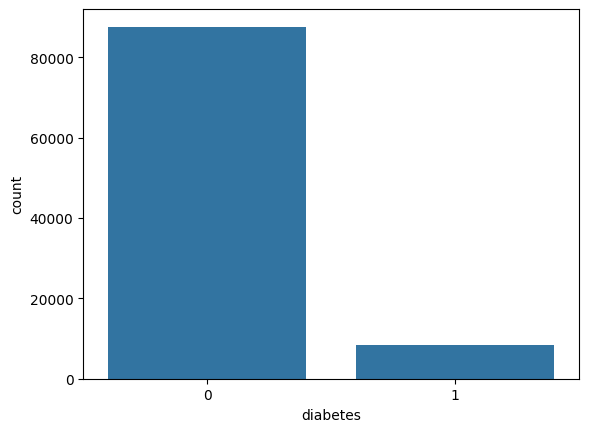

In [ ]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [ ]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
X = df.drop(columns='diabetes')
y = df['diabetes']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print(y_train.mean().round(4), y_test.mean().round(4))

(76916, 8) (19230, 8)
0.0882 0.0882


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [ ]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).
X_train = pd.get_dummies(X_train, columns=['gender', 'smoking_history'], dtype=int)
X_test = pd.get_dummies(X_test, columns=['gender', 'smoking_history'], dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print(X_train.shape, X_test.shape)
print(list(X_train.columns))

(76916, 15) (19230, 15)
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Female', 'gender_Male', 'gender_Other', 'smoking_history_No Info', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']


In [ ]:
# TODO: виведіть статистики опису X_train.
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
age,76916.0,41.760982,22.467762,0.08,24.00,43.00,59.00,80.00
hypertension,76916.0,0.078007,0.268185,0.00,0.00,0.00,0.00,1.00
heart_disease,76916.0,0.040876,0.198004,0.00,0.00,0.00,0.00,1.00
bmi,76916.0,27.313739,6.757207,10.01,23.39,27.32,29.85,95.22
HbA1c_level,76916.0,5.530527,1.072421,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,76916.0,138.114281,40.896909,80.00,100.00,140.00,159.00,300.00
gender_Female,76916.0,0.582675,0.493121,0.00,0.00,1.00,1.00,1.00
gender_Male,76916.0,0.417143,0.493090,0.00,0.00,0.00,1.00,1.00
gender_Other,76916.0,0.000182,0.013490,0.00,0.00,0.00,0.00,1.00
smoking_history_No Info,76916.0,0.342022,0.474390,0.00,0.00,0.00,1.00,1.00


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [ ]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
X_train.corrwith(y_train).sort_values(ascending=False)

,0
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_former,0.096162
gender_Male,0.040650
smoking_history_never,0.025725
smoking_history_ever,0.020899


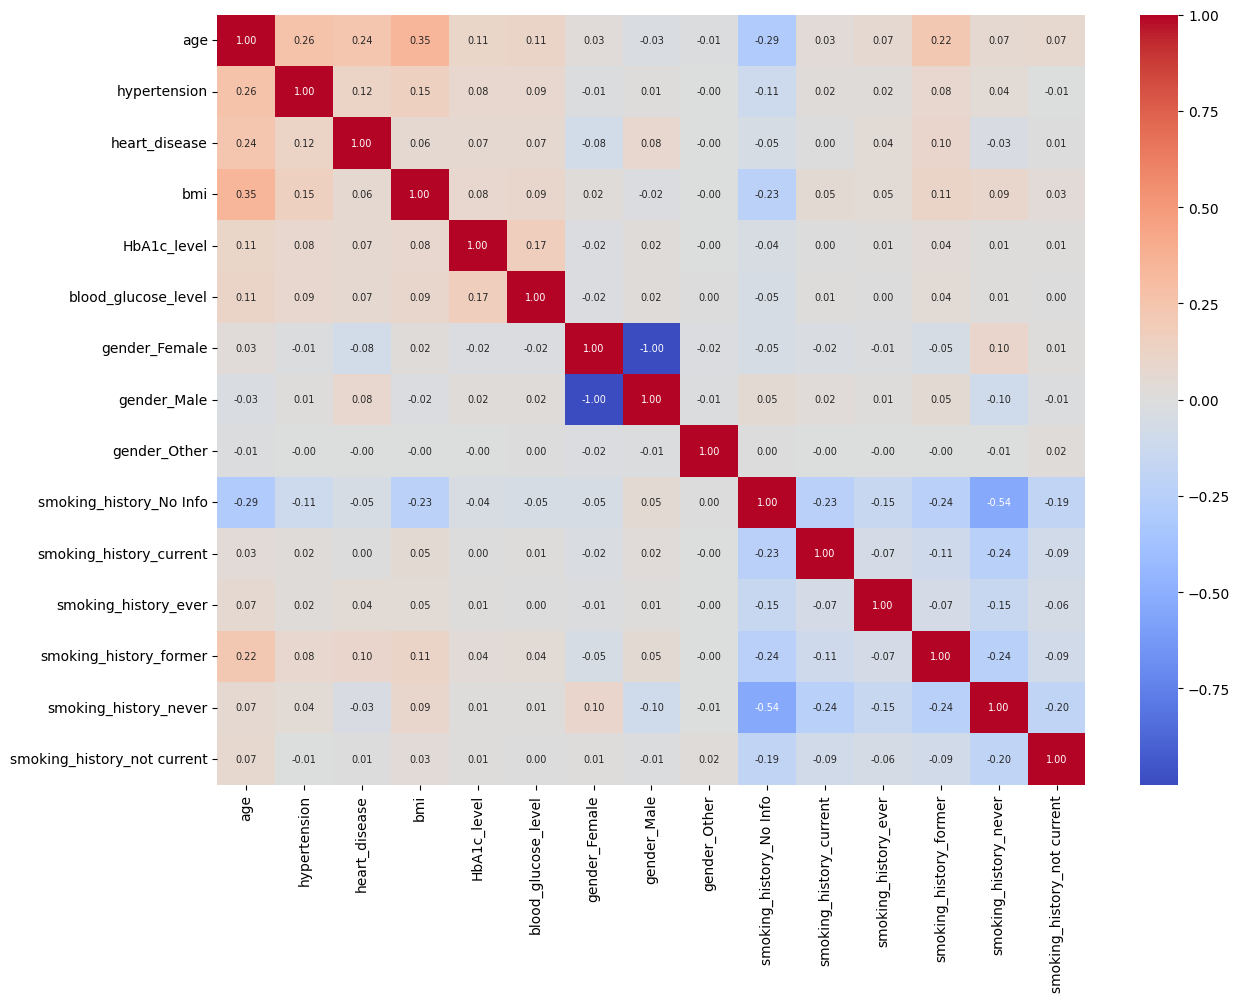

,,0
gender_Female,gender_Male,-0.999626
smoking_history_No Info,smoking_history_never,-0.537979


In [ ]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
corr_matrix = X_train.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.show()

corr_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)).stack()
corr_pairs[corr_pairs.abs() > 0.5].sort_values(key=abs, ascending=False)

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Найсильніше з цільовою змінною на train корелюють blood_glucose_level (0,42) і HbA1c_level (0,41), далі age (0,27), bmi (0,21), hypertension (0,20) та heart_disease (0,17). Це клінічно очікувано, адже рівень глюкози й HbA1c є прямими показниками діабету. Кореляції категоріальних індикаторів із цільовою змінною слабкі (до 0,11 за модулем). Між самими ознаками сильна кореляція є лише між gender_Female і gender_Male (близько -1), що є наслідком One-Hot кодування, та помірна між smoking_history_No Info і smoking_history_never (-0,54). Усі інші пари ознак мають |r| не більше 0,5, тому мультиколінеарності немає. Видаляти ознаки не потрібно: числові ознаки несуть самостійну інформацію про ціль, а залежність між бінарними індикаторами не шкодить регуляризованим моделям. Рішення прийнято лише за даними train.

Перевірити викиди **лише на навчальній вибірці**

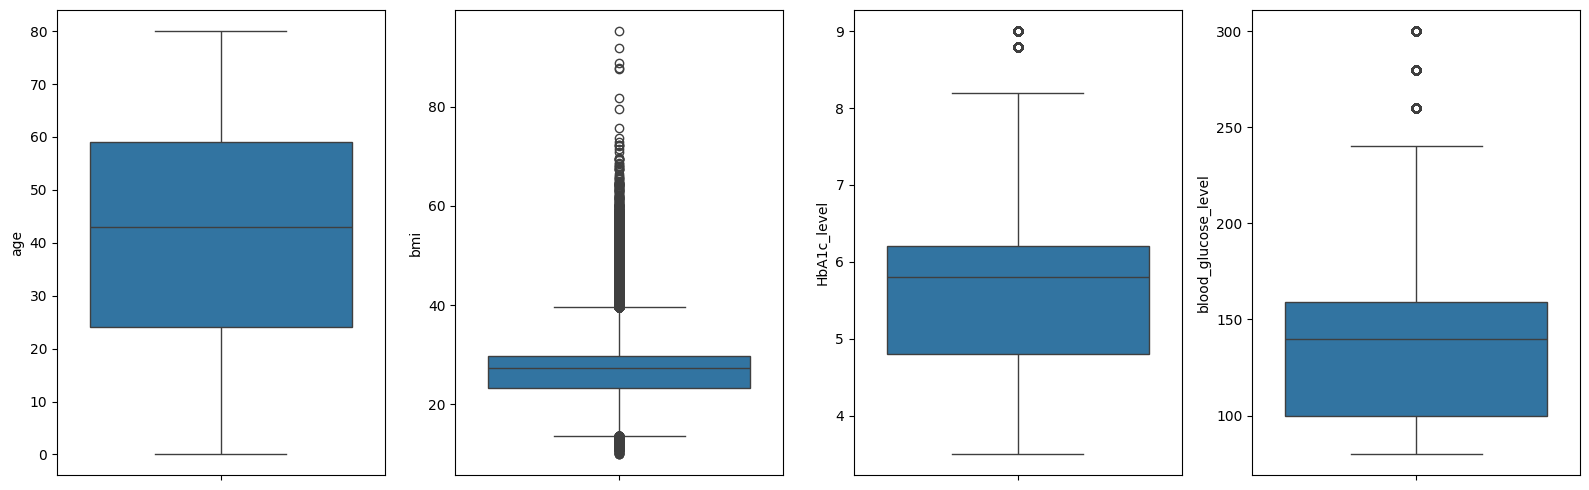

,кількість,"частка, %"
age,0,0.00
bmi,4244,5.52
HbA1c_level,1041,1.35
blood_glucose_level,1598,2.08


In [ ]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(y=X_train[col], ax=ax)
plt.tight_layout()
plt.show()

q1 = X_train[continuous_cols].quantile(0.25)
q3 = X_train[continuous_cols].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = (X_train[continuous_cols] < lower) | (X_train[continuous_cols] > upper)
pd.DataFrame({'кількість': outliers.sum(), 'частка, %': (outliers.mean() * 100).round(2)})

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [ ]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
X_train[continuous_cols].skew()

,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [ ]:
# TODO: перевірте пропуски окремо в X_train та X_test.
pd.DataFrame({'X_train': X_train.isnull().sum(), 'X_test': X_test.isnull().sum()})

,X_train,X_test
age,0,0
hypertension,0,0
heart_disease,0,0
bmi,0,0
HbA1c_level,0,0
blood_glucose_level,0,0
gender_Female,0,0
gender_Male,0,0
gender_Other,0,0
smoking_history_No Info,0,0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

На train частка класу diabetes = 1 становить близько 8,8%, тобто завдяки stratify дисбаланс класів збережено. Найсильніший зв'язок із цільовою змінною мають blood_glucose_level і HbA1c_level, сильних кореляцій між змістовими ознаками немає. За правилом IQR потенційні викиди на train є в bmi (4244 значення, 5,52%), blood_glucose_level (1598, 2,08%) та HbA1c_level (1041, 1,35%), а в age викидів немає. Ознаки bmi (асиметрія 1,01) і blood_glucose_level (0,83) мають помірну правосторонню асиметрію, а age (-0,06) та HbA1c_level (-0,06) майже симетричні. Викиди не видалялись, бо високі значення глюкози й HbA1c можуть бути клінічно важливими. Пропусків у X_train та X_test немає, тестова вибірка залишена без змін.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [ ]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.shape, X_test_scaled.shape)

(76916, 15) (19230, 15)


Балансуємо лише навчальну вибірку за допомогою SMOTE

In [ ]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)
pd.DataFrame({'до SMOTE': y_train.value_counts(), 'після SMOTE': y_train_res.value_counts()})

,до SMOTE,після SMOTE
diabetes,,
0,70130,70130
1,6786,70130


Після SMOTE навчальна вибірка збалансована: по 70130 об'єктів кожного класу, тоді як раніше було 70130 і 6786. SMOTE застосовано лише до масштабованої навчальної вибірки, а тестова залишилась природно незбалансованою, щоб оцінка відповідала реальному розподілу класів.

Оголошуємо моделі

In [ ]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.
models = {
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=42),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42),
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


LogisticRegression
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



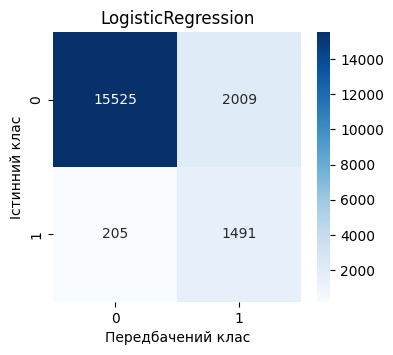

RidgeClassifier
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



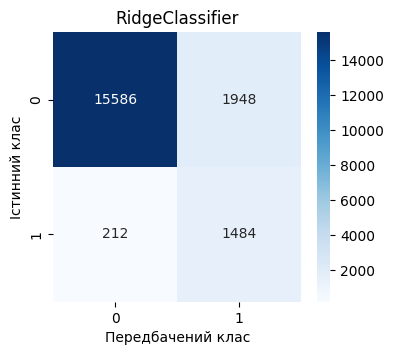

SGDClassifier
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.54      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



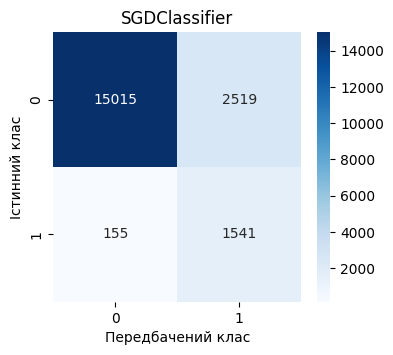

KeyboardInterrupt: 

In [29]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).
baseline_scores = {}
for name, model in models.items():
    model.fit(X_train_res, y_train_res)
    y_pred = model.predict(X_test_scaled)
    print(name)
    print(classification_report(y_test, y_pred))
    rep = classification_report(y_test, y_pred, output_dict=True)['1']
    baseline_scores[name] = {'precision': rep['precision'], 'recall': rep['recall'], 'f1': rep['f1-score']}
    plt.figure(figsize=(4, 3.5))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title(name)
    plt.xlabel('Передбачений клас')
    plt.ylabel('Істинний клас')
    plt.show()
pd.DataFrame(baseline_scores).T.round(4)

Оптимізувати гіперпараметри


In [30]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.
param_grids = {
    'LogisticRegression': {'model__C': [0.01, 0.1, 1, 10], 'model__solver': ['lbfgs', 'liblinear']},
    'RidgeClassifier': {'model__alpha': [0.1, 1, 10, 100]},
    'SGDClassifier': {'model__loss': ['hinge', 'log_loss', 'modified_huber'], 'model__penalty': ['l2', 'l1', 'elasticnet']},
    'SVC': {'model__C': [0.1, 1, 10], 'model__kernel': ['linear', 'rbf']},
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [31]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

LogisticRegression
Оптимальні параметри: {'model__C': 1, 'model__solver': 'lbfgs'}
Середній F1 на кросвалідації: 0.6098
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



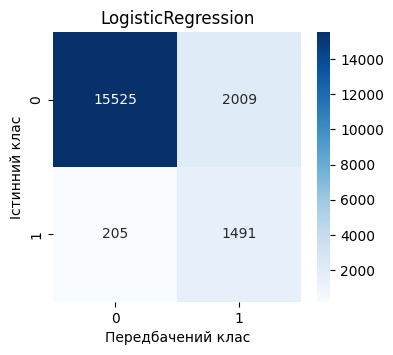

RidgeClassifier
Оптимальні параметри: {'model__alpha': 100}
Середній F1 на кросвалідації: 0.6587
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



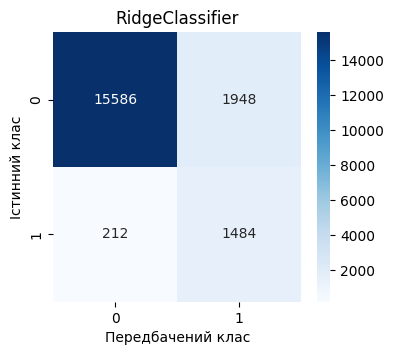

SGDClassifier
Оптимальні параметри: {'model__loss': 'log_loss', 'model__penalty': 'l2'}
Середній F1 на кросвалідації: 0.6059
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



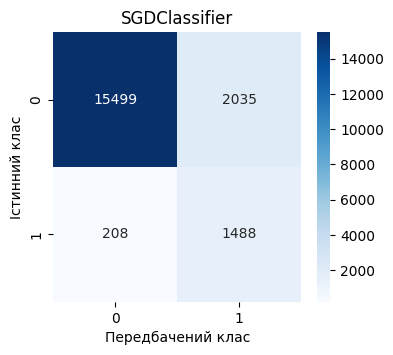

SVC
Оптимальні параметри: {'model__C': 1, 'model__kernel': 'linear'}
Середній F1 на кросвалідації: 0.5892
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.89      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



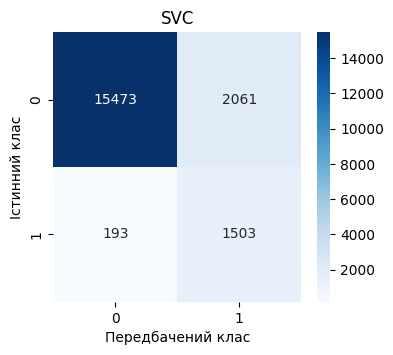

In [ ]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.
from sklearn.base import clone

best_models = {}
best_scores = {}
for name, model in models.items():
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', clone(model)),
    ])
    search = HalvingGridSearchCV(pipeline, param_grids[name], cv=3, scoring='f1', min_resources=300, random_state=42, n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_
    y_pred = search.predict(X_test)
    print(name)
    print('Оптимальні параметри:', search.best_params_)
    print('Середній F1 на кросвалідації:', round(search.best_score_, 4))
    print(classification_report(y_test, y_pred))
    plt.figure(figsize=(4, 3.5))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title(name)
    plt.xlabel('Передбачений клас')
    plt.ylabel('Істинний клас')
    plt.show()

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.
best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]
print(best_name, round(best_scores[best_name], 4))
pd.Series(best_scores).round(4)

RidgeClassifier 0.6587


,0
LogisticRegression,0.6098
RidgeClassifier,0.6587
SGDClassifier,0.6059
SVC,0.5892


За середнім F1 на кросвалідації найкращою обрано модель RidgeClassifier (0,6587 за alpha = 100), далі LogisticRegression (0,6098), SGDClassifier (0,6059) та SVC (0,5892). Вибір зроблено за кросвалідацією на train, а не за тестовою вибіркою, щоб тестові дані не впливали на вибір моделі. HalvingGridSearchCV спочатку оцінює кандидатів на малих підвибірках, тому ці значення F1 відрізняються від F1 на тестовій вибірці (0,57-0,58), але для порівняння моделей між собою їх достатньо.

In [ ]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.
sample_idx = X_test.sample(10, random_state=42).index
comparison = pd.DataFrame({
    'індекс': sample_idx,
    'істинний клас': y_test.loc[sample_idx].values,
    'передбачений клас': best_model.predict(X_test.loc[sample_idx]),
})
comparison

,індекс,істинний клас,передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


З 10 випадкових тестових записів усі мають істинний клас 0, що відповідає великій частці здорових пацієнтів у даних. RidgeClassifier правильно передбачив клас 0 у 8 випадках, а у двох (індекси 29668 і 8912) помилково передбачив діабет. Це узгоджується з низькою precision моделі для класу 1 (близько 0,43): модель нерідко дає хибні тривоги. Оскільки серед вибраних записів немає жодного хворого, за цією вибіркою не можна оцінити recall.

**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

Дисбаланс класів значний: клас diabetes = 1 становить 8,5% у вихідних даних і 8,8% після видалення 3854 дублікатів (8482 хворих проти 87664 здорових), тому accuracy для оцінки не підходить і основними метриками є precision, recall та F1 для класу 1. На train найсильніше з ціллю корелюють blood_glucose_level (0,42) і HbA1c_level (0,41), сильних кореляцій між змістовими ознаками немає, тому ознаки не видалялись. Викиди за IQR є в bmi (5,52%), blood_glucose_level (2,08%) та HbA1c_level (1,35%), але їх не видаляли, бо екстремальні значення глюкози й HbA1c клінічно важливі.

Усі чотири базові моделі мають високий recall для класу 1 (0,88-0,91) і низьку precision (0,38-0,43), F1 становить 0,54-0,58. Найвищий recall у SGDClassifier та SVC (0,91), найвищий F1 у SVC і RidgeClassifier (0,58), але різниця між моделями невелика. За середнім F1 на кросвалідації обрано RidgeClassifier (0,6587), далі йдуть LogisticRegression (0,6098), SGDClassifier (0,6059) і SVC (0,5892).

Оптимальні гіперпараметри: LogisticRegression C = 1 і solver = lbfgs, RidgeClassifier alpha = 100, SGDClassifier loss = log_loss і penalty = l2, SVC C = 1 і kernel = linear. Після підбору тестові метрики майже не змінились (F1 класу 1 близько 0,57-0,58), тобто обмеження моделей пов'язане не з гіперпараметрами, а з їх лінійністю. У матрицях плутанини переважають хибнопозитивні помилки: приблизно 57% позитивних прогнозів помилкові (precision близько 0,43), а пропущених хворих значно менше (recall близько 0,88). Імовірно, це наслідок балансування SMOTE, яке зсуває межу рішення в бік класу 1.

Тестові дані відкладають і виконують масштабування та SMOTE лише на train, щоб уникнути витоку даних. Якщо обчислювати середнє та стандартне відхилення за всією вибіркою, інформація про test потрапить у навчання. Якщо застосувати SMOTE до поділу, синтетичні об'єкти будуть створені на основі майбутніх тестових записів і дуже схожі на них, через що метрики на test стануть завищеними. Тестова вибірка має залишатися незмінною та незбалансованою, щоб оцінка відповідала реальному розподілу класів. З цієї ж причини в HalvingGridSearchCV масштабування та SMOTE винесено в Pipeline і виконуються окремо в кожному навчальному згині кросвалідації.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

XGBoost
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.92      0.71      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



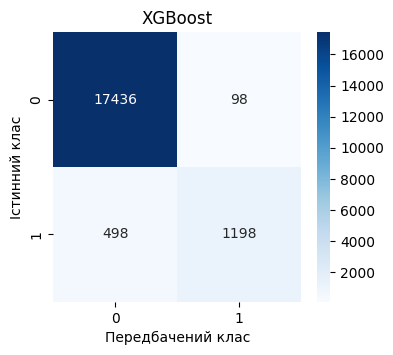

LightGBM
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.94      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



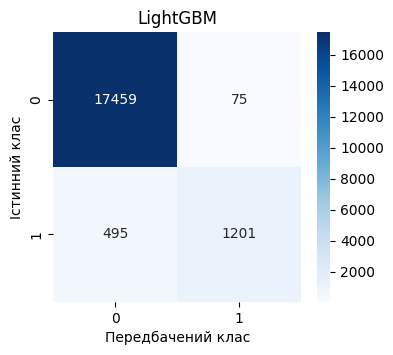

CatBoost
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.93      0.71      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



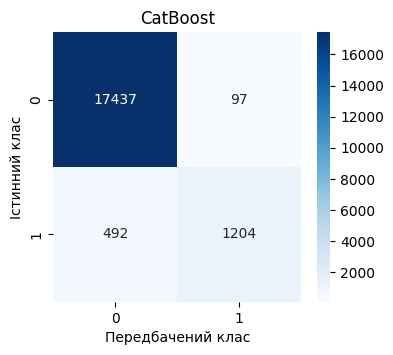

,precision,recall,f1
LogisticRegression,0.4260,0.8791,0.5739
RidgeClassifier,0.4324,0.8750,0.5788
SGDClassifier,0.3796,0.9086,0.5354
SVC,0.4253,0.9074,0.5791
XGBoost,0.9244,0.7064,0.8008
LightGBM,0.9412,0.7081,0.8082
CatBoost,0.9254,0.7099,0.8035


In [ ]:
!pip install -q catboost

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

boosting_models = {
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0),
}

X_train_boost = pd.DataFrame(X_train_res, columns=X_train.columns)
X_test_boost = pd.DataFrame(X_test_scaled, columns=X_train.columns)

boosting_scores = {}
for name, model in boosting_models.items():
    model.fit(X_train_boost, y_train_res)
    y_pred = model.predict(X_test_boost)
    print(name)
    print(classification_report(y_test, y_pred))
    rep = classification_report(y_test, y_pred, output_dict=True)['1']
    boosting_scores[name] = {'precision': rep['precision'], 'recall': rep['recall'], 'f1': rep['f1-score']}
    plt.figure(figsize=(4, 3.5))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title(name)
    plt.xlabel('Передбачений клас')
    plt.ylabel('Істинний клас')
    plt.show()

pd.concat([pd.DataFrame(baseline_scores).T, pd.DataFrame(boosting_scores).T]).round(4)

Три бустингові моделі показали близькі результати: XGBoost (precision 0,92, recall 0,71, F1 0,80), LightGBM (0,94; 0,71; 0,81) і CatBoost (0,93; 0,71; 0,80) за загальної точності 0,97. За F1 і precision для класу diabetes = 1 вони значно кращі за LogisticRegression, RidgeClassifier, SGDClassifier та SVC (F1 0,54-0,58, precision 0,38-0,43). Натомість recall бустингів (0,71) нижчий, ніж у базових моделей (0,88-0,91): бустинги рідше хибно визначають діабет, але пропускають близько 29% хворих, тоді як лінійні моделі виявляють більшість хворих ціною великої кількості хибних тривог. Імовірна причина переваги бустингів у здатності дерев вловлювати нелінійні пороги, наприклад для HbA1c_level і blood_glucose_level. Найкращий баланс за F1 має LightGBM, але різниця між трьома моделями дуже мала. Бустингові моделі навчались із параметрами за замовчуванням, без підбору гіперпараметрів. Для медичного скринінгу, де пропуск хворого небезпечний, може бути важливіше підвищити recall, наприклад зниженням порога класифікації.